# EDA cổ phiếu FPT — snapshot v2

Khảo sát chất lượng nguồn, giá điều chỉnh, phân phối lợi suất và tương quan đặc trưng. Đây là mô tả hậu nghiệm sau lượt train đã khóa; không dùng test 2025 để tuning. Tương quan không phải quan hệ nhân quả.

In [1]:
from pathlib import Path
import os, sys, json, subprocess, importlib.metadata
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path('/content/FPT_Stock_Forecasting_portable_v2')
    if not (ROOT / '.git').exists():
        subprocess.check_call(['git', 'clone', '--depth', '1', '--branch', 'feature/train-model',
                               'https://github.com/PhucTruong11/FPT_Stock_Forecasting.git', str(ROOT)])
    loaded_versions = {name: getattr(sys.modules.get(name), '__version__', None)
                       for name in ['numpy', 'pandas', 'sklearn', 'tensorflow', 'xgboost']}
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements-colab.txt')])
    packages = {'sklearn': 'scikit-learn', 'numpy': 'numpy', 'pandas': 'pandas', 'tensorflow': 'tensorflow', 'xgboost': 'xgboost'}
    changed = [name for name, old in loaded_versions.items()
               if old is not None and old != importlib.metadata.version(packages[name])]
    if changed:
        raise RuntimeError('Dependencies changed: ' + str(changed) + '. Restart the Colab session, then Run all again.')
else:
    candidates = [Path(os.environ.get('FPT_PROJECT_ROOT', Path.cwd())), Path.cwd(), *Path.cwd().parents]
    ROOT = next((p for p in candidates if (p / 'src/models/experiment.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open the complete updated project.')
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data.snapshot import restore_snapshot
restore_snapshot(ROOT)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.models.experiment import load_data, split_masks, run_experiment, evaluate_saved
from src.features.build_features import FEATURE_COLUMNS, TARGET_COLUMN
plt.rcParams.update({'figure.figsize': (11, 4), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})
print('Project:', ROOT)
print('Exact shared snapshot restored; no Yahoo download.')


Project: D:\Dev\Subject_Uni\Machine_Learning\Stock_Prediction_Project
Exact shared snapshot restored; no Yahoo download.


## 1. Chất lượng và phạm vi dữ liệu

In [2]:
features, labels, metadata = load_data(ROOT)
raw = pd.read_csv(ROOT / 'data/raw/FPT.VN_raw.csv', parse_dates=['Date'])
excluded = pd.read_csv(ROOT / 'data/processed/FPT.VN_excluded_rows.csv')
display(pd.Series({key: metadata[key] for key in ['raw_rows', 'zero_volume_excluded', 'invalid_candle_excluded', 'eligible_rows', 'warmup_rows', 'feature_rows', 'labeled_rows']}))
display(excluded['Reason'].value_counts().rename_axis('reason').to_frame('rows'))
print('Raw dates:', raw.Date.min(), raw.Date.max())
print('Positive-volume observations are not independently verified HOSE sessions.')

raw_rows                   2088
zero_volume_excluded        147
invalid_candle_excluded       1
eligible_rows              1940
warmup_rows                  49
feature_rows               1891
labeled_rows               1889
dtype: int64

,rows
reason,
zero_volume_excluded_not_confirmed_holiday,143
zero_volume_and_missing_prices,4
invalid_ohlc_candle,1


Raw dates: 2018-01-01 00:00:00 2025-12-31 00:00:00
Positive-volume observations are not independently verified HOSE sessions.


## 2. Giá và lợi suất theo thời gian

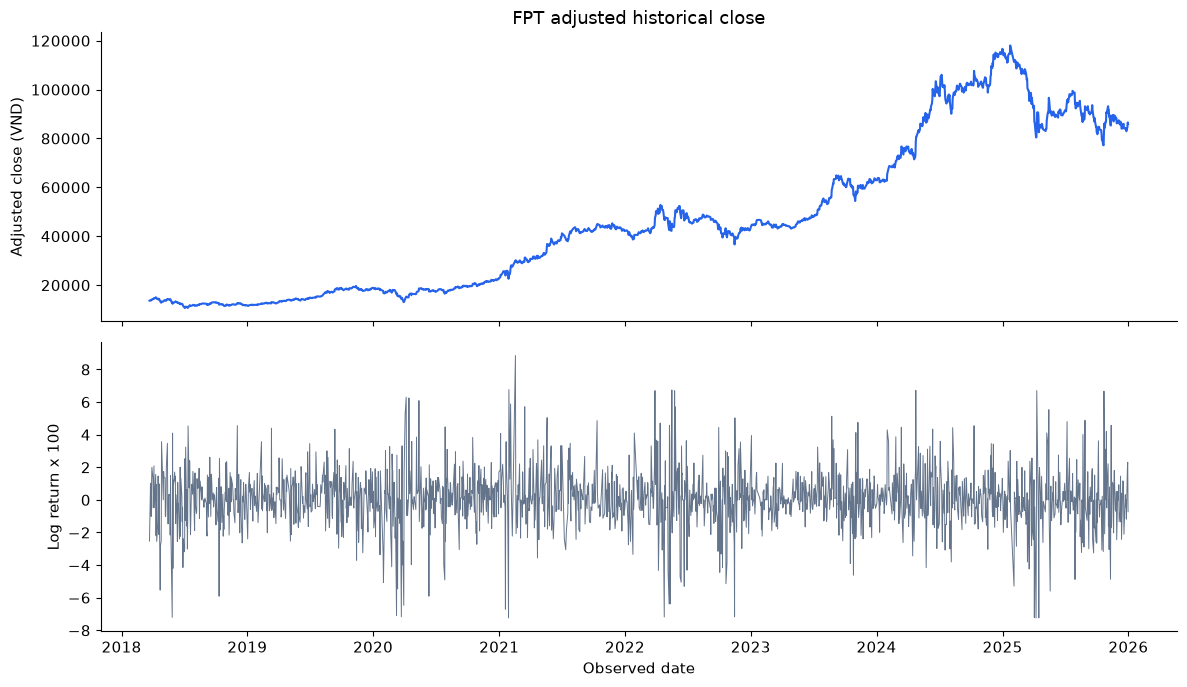

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
axes[0].plot(features['Date'], features['Close'], color='#2563eb')
axes[0].set(ylabel='Adjusted close (VND)', title='FPT adjusted historical close')
axes[1].plot(features['Date'], features['Log_Return'] * 100, color='#64748b', linewidth=.7)
axes[1].set(ylabel='Log return x 100', xlabel='Observed date')
fig.tight_layout()
plt.show()

## 3. Phân phối lợi suất và tỷ lệ tăng/giảm

,split,n,mean,std,up,down,neutral
0,train,1087,0.001159,0.017989,553,464,70
1,validation,493,0.001956,0.013973,254,210,29
2,test,248,-0.001221,0.019920,95,116,37


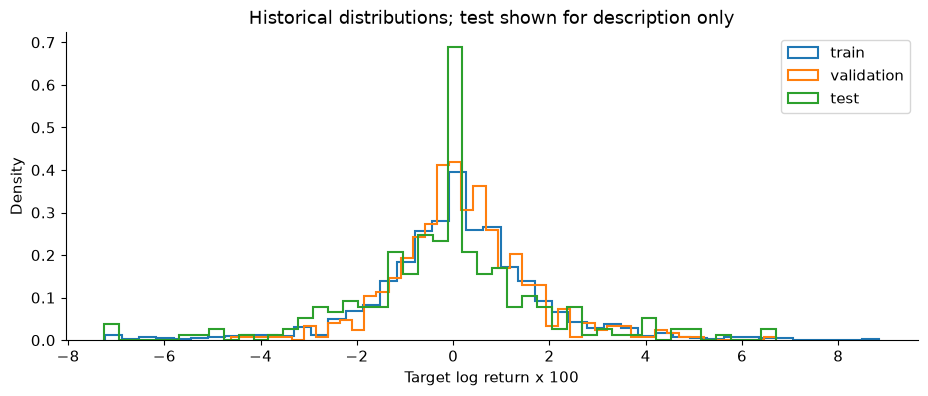

In [4]:
masks = split_masks(labels)
rows = []
fig, ax = plt.subplots(figsize=(11, 4))
for name, mask in masks.items():
    values = labels.loc[mask, TARGET_COLUMN]
    rows.append({'split': name, 'n': len(values), 'mean': values.mean(), 'std': values.std(),
                 'up': int((values > 0).sum()), 'down': int((values < 0).sum()), 'neutral': int((values == 0).sum())})
    ax.hist(values * 100, bins=45, density=True, histtype='step', linewidth=1.5, label=name)
display(pd.DataFrame(rows))
ax.set(xlabel='Target log return x 100', ylabel='Density', title='Historical distributions; test shown for description only')
ax.legend()
plt.show()

## 4. Tương quan trên train

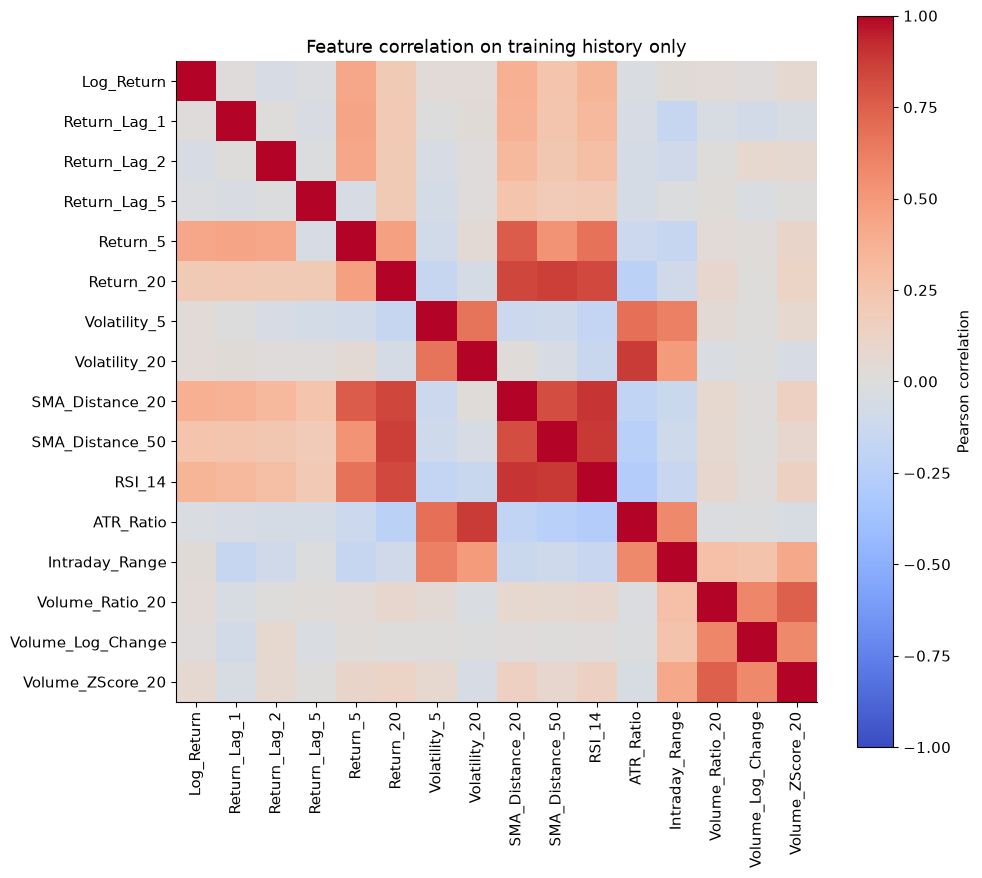

In [5]:
corr = labels.loc[masks['train'], FEATURE_COLUMNS].corr()
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS, rotation=90)
ax.set_yticks(range(len(FEATURE_COLUMNS)), FEATURE_COLUMNS)
ax.set_title('Feature correlation on training history only')
fig.colorbar(image, ax=ax, label='Pearson correlation')
fig.tight_layout()
plt.show()

## Điều cần kiểm chứng tiếp

- Đối soát lịch giao dịch và corporate actions với nguồn độc lập.
- Các feature cùng nhóm return/SMA có thể trùng thông tin; kiểm chứng bằng ablation trên development.
- Phân phối thay đổi giữa các giai đoạn; một split lịch sử chưa đủ chứng minh tổng quát hóa.
- Volume bằng 0 và OHLC lỗi đã được cách ly, không khẳng định toàn bộ là ngày nghỉ.